# Class 1 - From a regression line to a neural network

**AI in Quantitative Biology (Univ. Milano, 2026) - class 1 of 3, 150 min**

Goes with `basics_slides.pptx` in this folder. The lecture made three claims that this notebook puts in your hands, on real data:

1. Fitting a model is **induction** - you guess a rule from observations, and the rule is only ever
   probabilistic (slides 6-9).
2. An artificial neuron **is** a linear regression with a nonlinearity bolted on (slides 12-14), and a
   network is just many of them (slides 18-21).
3. Training means **walking downhill on a loss function** (slides 22, 24-25), and if you walk too far
   you overfit, which is why a test set exists (slides 26-28).

The data: 908 chemicals with 6 molecular descriptors each, and their measured acute toxicity to the
fathead minnow (*Pimephales promelas*), 96-hour LC50. The target is `-log10(mol/L)`, so **larger means
more toxic**. This is a real QSAR dataset, small enough that every experiment below finishes in seconds.

Exercises are marked ✏️ and open questions ❓. **The answers are in this notebook**, in the cell right
after the question - try it yourself before you open them.

## Setup

In [ ]:
# @title Setup: imports, data loading and helpers (run me)

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")          # sklearn convergence chatter, not interesting here
RNG = 0                                    # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)


UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/{id}/{name}"
UCI_FILES = {"qsar_fish_toxicity.csv": "00504", "qsar_aquatic_toxicity.csv": "00505"}


def find_data_dir():
    """$QBIO_DATA if set, else the `data/` folder of the course repository (here or above).
    If neither exists (e.g. Colab, or just the notebook downloaded), fetch the two QSAR
    files from UCI into ./qsar_data/ -- enough for this class only."""
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "qsar_fish_toxicity.csv").exists():
            return p / "data"
    import urllib.request
    d = here / "qsar_data"
    d.mkdir(exist_ok=True)
    for name, uci_id in UCI_FILES.items():
        if not (d / name).exists():
            urllib.request.urlretrieve(UCI_URL.format(id=uci_id, name=name), d / name)
    warnings.simplefilter("always")
    warnings.warn(
        "\n\n  Course data folder NOT found: the two QSAR files were downloaded from UCI instead.\n"
        "  This is enough for Class 1, but Classes 2 and 3 need enzymes.tsv and targeting.tsv,\n"
        "  which are only in the course git repository. They will NOT work unless you run them\n"
        "  from a cloned copy of the repo (git clone <repo URL>, then open the notebooks there).\n",
        stacklevel=2)
    warnings.simplefilter("ignore")
    return d


DATA_DIR = find_data_dir()
print("data from", DATA_DIR)

FISH_COLUMNS = ["CIC0", "SM1_Dz", "GATS1i", "NdsCH", "NdssC", "MLOGP", "LC50"]
AQUATIC_COLUMNS = ["TPSA", "SAacc", "H050", "MLOGP", "RDCHI", "GATS1p", "nN", "C040", "LC50"]


def load_fish():
    """Fathead minnow 96 h LC50 for 908 chemicals (UCI QSAR fish toxicity)."""
    return pd.read_csv(DATA_DIR / "qsar_fish_toxicity.csv", sep=";", header=None, names=FISH_COLUMNS)


def load_aquatic():
    """Daphnia magna 48 h LC50 for 546 chemicals (UCI QSAR aquatic toxicity)."""
    return pd.read_csv(DATA_DIR / "qsar_aquatic_toxicity.csv", sep=";", header=None, names=AQUATIC_COLUMNS)


def xy(df):
    """Descriptor matrix and target vector."""
    return df.drop(columns="LC50").values, df["LC50"].values

data from /Users/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


## Part 1 - Induction: a rule guessed from observations

Slide 6 contrasts deduction (*theory → observation*) with induction (*observation → rule*). Machine
learning is industrial-scale induction, and slide 8 warns with an asterisk that letting computers do it
is **dangerous**. Before any model, look at what we are inducing from.

**The dataset** (Cassotti et al. 2015, UCI repository) lists **908 chemicals** tested on the fathead
minnow (*Pimephales promelas*), a standard test fish. For each chemical:

* **`LC50`** (the target): the concentration that kills 50% of the fish in 96 hours, given as
  $-\log_{10}(\text{mol/L})$. **Larger = more toxic** (less substance needed).
* six **molecular descriptors** (the inputs), computed from the structure alone:

| descriptor | meaning (Cassotti et al. 2015) | reading |
|---|---|---|
| `MLOGP` | Moriguchi estimate of the octanol/water partition coefficient logP (regression on 13 structural parameters) | **lipophilicity** ("how fatty"); +1 = 10x more partitioning into fat |
| `CIC0` | complementary information content of order 0: how far the atom-class entropy is below its maximum; counts *distinct elements*, not atoms | falls as more different elements are present, i.e. a **heteroatom-diversity** index (not size) |
| `SM1_Dz` | first spectral moment of the Barysz matrix weighted by atomic number (sum of its eigenvalues; bond order + atomic number) | tracks the **number of heteroatoms** (rho = 0.86): lowest for all-carbon molecules, highest for fluorinated/chlorinated ones |
| `GATS1i` | autocorrelation of ionisation potential between bonded atoms | low for many C-C bonds (rho = -0.79 with % carbon), Br/I and aromatics, so a second **lipophilicity proxy** |
| `NdsCH` | number of `=CH-` atoms (sp2 carbon with one H); atom-type E-state count | flags **electrophilic** groups (aldehydes, imines, C=C...); low PCA loading, mostly helps the kNN find similar neighbours |
| `NdssC` | number of `=C<` atoms (sp2 carbon with no H); atom-type E-state count | same role (ketones, esters, amides, acids...) |

In [ ]:
fish = load_fish()
print(fish.shape)
fish.head()

(908, 7)


,CIC0,SM1_Dz,GATS1i,NdsCH,NdssC,MLOGP,LC50
0,3.260,0.829,1.676,0,1,1.453,3.770
1,2.189,0.580,0.863,0,0,1.348,3.115
2,2.125,0.638,0.831,0,0,1.348,3.531
3,3.027,0.331,1.472,1,0,1.807,3.510
4,2.094,0.827,0.860,0,0,1.886,5.390


In [ ]:
fish.describe()

,CIC0,SM1_Dz,GATS1i,NdsCH,NdssC,MLOGP,LC50
count,908.000,908.000,908.000,908.000,908.000,908.000,908.000
mean,2.898,0.628,1.294,0.229,0.486,2.109,4.064
std,0.756,0.428,0.394,0.605,0.861,1.433,1.456
min,0.667,0.000,0.396,0.000,0.000,-2.884,0.053
25%,2.347,0.223,0.951,0.000,0.000,1.209,3.152
50%,2.934,0.570,1.240,0.000,0.000,2.127,3.987
75%,3.407,0.893,1.562,0.000,1.000,3.105,4.907
max,5.926,2.171,2.920,4.000,6.000,6.515,9.612


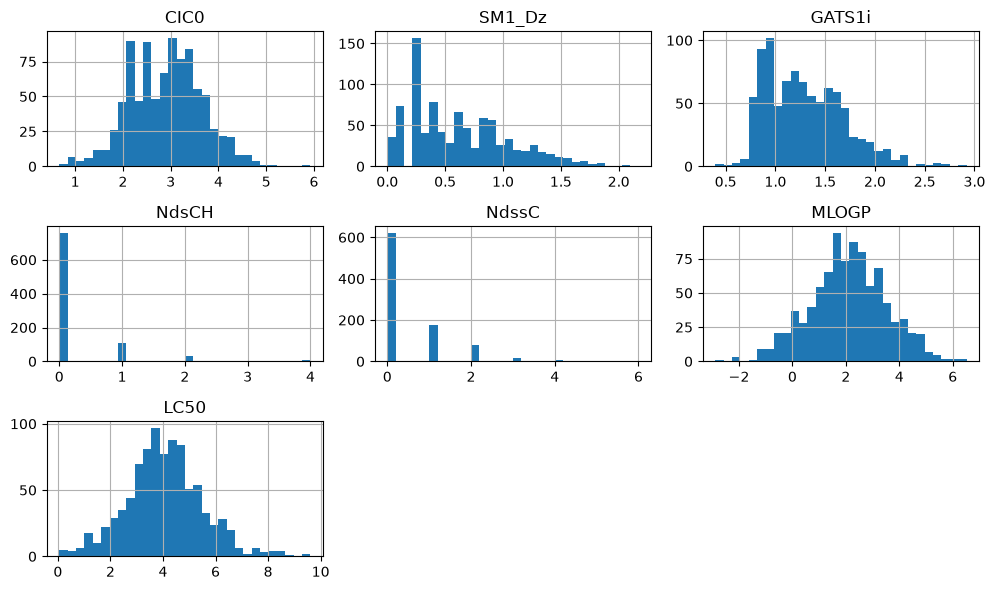

In [ ]:
fish.hist(bins=30, figsize=(10, 6))
plt.tight_layout()

✏️ **Warm-up.** Answer with one line of pandas each:
1. Which descriptors are **counts** (only integer values)? *Hint:* `fish[col].nunique()` or look at the histograms.
2. What is the LC50 of the **most toxic** chemical, and in which row is it? *Hint:* `.max()`, `.idxmax()`.
3. How many chemicals have an LC50 above 6 (i.e. lethal below 1 µmol/L)?

In [ ]:
# 1. counts have few distinct values
print(fish.nunique())
# 2.
print("max LC50:", fish["LC50"].max(), "in row", fish["LC50"].idxmax())
# 3.
print((fish["LC50"] > 6).sum(), "chemicals with LC50 > 6")

CIC0      502
SM1_Dz    186
GATS1i    557
NdsCH       5
NdssC       7
MLOGP     559
LC50      827
dtype: int64
max LC50: 9.612 in row 259
87 chemicals with LC50 > 6


❓ An LC50 of 6 means $10^{-6}$ mol/L. What is the difference in lethal concentration between a
chemical with LC50 = 3 and one with LC50 = 6?

<details><summary>Show answer</summary>

**Answer.** The scale is logarithmic: 3 units = a factor of $10^3$ = **1000 times** less substance is
needed. NdsCH and NdssC are the counts. The most toxic chemical has LC50 ≈ 9.6.

</details>

The six descriptors are numbers a program computes from the molecular structure (slide 29 calls this
*featurization*). Only `MLOGP` has an everyday reading - how greasy the molecule is - the others are topological indices.

✏️ **Exercise 1.** Which single descriptor is most strongly associated with toxicity? Compute the
correlation of each descriptor with `LC50` and plot the best one against the target.

GATS1i   -0.398
NdsCH     0.172
NdssC     0.172
CIC0      0.292
SM1_Dz    0.411
MLOGP     0.652
Name: LC50, dtype: float64


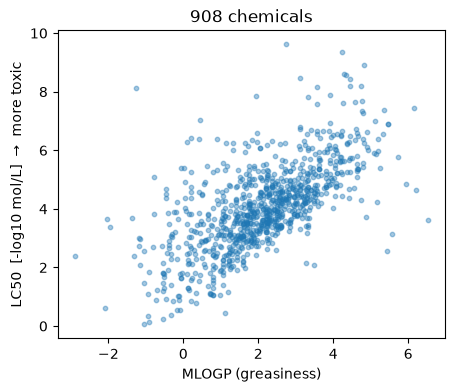

In [ ]:
print(fish.corr()["LC50"].drop("LC50").sort_values())

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(fish["MLOGP"], fish["LC50"], s=10, alpha=0.4)
ax.set_xlabel("MLOGP (greasiness)")
ax.set_ylabel("LC50  [-log10 mol/L]  →  more toxic")
ax.set_title("908 chemicals")
plt.show()

<details><summary>Show answer</summary>

**Answer.** `MLOGP`, at r = 0.65. Greasier molecules are more toxic - they cross membranes and partition
into lipid, the classical "narcosis" baseline of aquatic toxicology. `SM1_Dz` follows at 0.41 and
`GATS1i` is the one clearly *negative* association, -0.40.

Two things worth noticing on the scatter plot, because they come back all afternoon: the trend is real
but the scatter around it is wide, and there is no visible second cluster - one rule, with noise, is a
defensible assumption here.

</details>

### An unsupervised look: PCA

With 6 descriptors we cannot plot all the data at once. **Principal Component Analysis** finds the
directions along which the data vary the most and lets us draw a 2D "map" of the chemicals.
We do not give it LC50: we only colour the points by toxicity afterwards.

Descriptors have very different units, so we first **standardise** them (mean 0, std 1).

variance explained by PC1, PC2: [0.274 0.245]


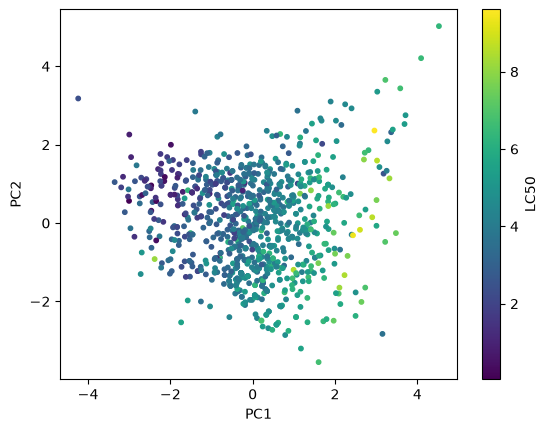

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = fish.drop(columns="LC50")
y = fish["LC50"]

Xs = StandardScaler().fit_transform(X)
pca = PCA(n_components=2).fit(Xs)
Z = pca.transform(Xs)
print("variance explained by PC1, PC2:", pca.explained_variance_ratio_.round(3))

plt.scatter(Z[:, 0], Z[:, 1], c=y, cmap="viridis", s=10)
plt.colorbar(label="LC50")
plt.xlabel("PC1"); plt.ylabel("PC2");

In [ ]:
# which descriptors make up each component ("loadings")?
pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"])

,PC1,PC2
CIC0,0.506,0.471
SM1_Dz,0.137,-0.479
GATS1i,-0.366,0.533
NdsCH,0.202,0.358
NdssC,0.267,0.315
MLOGP,0.692,-0.194


❓ Is toxicity organised along the map? Which descriptors dominate PC1?

<details><summary>Show answer</summary>

**Answer.** There is a colour gradient (toxic chemicals mostly on one side), but it is far from a
clean separation: two components capture only about half of the variance (27% + 25%) and toxicity
is only partly aligned with them. PC1 is mostly lipophilicity and complexity (`MLOGP`, `CIC0`);
PC2 contrasts `GATS1i`/`CIC0` with `SM1_Dz`. PCA is a good first look, not a predictor.

</details>

## Part 2 - Regression as a box with parameters inside

Slide 12 draws regression as a box: inputs $x_1, x_2$ go in, weights $w_1, w_2, w_3$ sit inside, a number
comes out.

$$y(x_1, x_2 \mid w) = w_1 x_1 + w_2 x_2 + w_3$$

We *assumed* the functional form (a plane) and we *induce* the weights. Let us do exactly that: first
with one descriptor, then with all six.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(5, shuffle=True, random_state=RNG)
X, y = xy(fish)

one = LinearRegression().fit(fish[["MLOGP"]], y)
print(f"one descriptor:  LC50 = {one.coef_[0]:.3f} * MLOGP + {one.intercept_:.3f}")
print("  5-fold CV R2 =", round(cross_val_score(LinearRegression(), fish[["MLOGP"]], y, cv=cv, scoring="r2").mean(), 3))

allsix = LinearRegression().fit(X, y)
print("\nall six descriptors:")
for name, w in zip(FISH_COLUMNS[:-1], allsix.coef_):
    print(f"  {name:>7s}  {w:+.3f}")
print(f"  {'bias':>7s}  {allsix.intercept_:+.3f}")
scores = cross_val_score(LinearRegression(), X, y, cv=cv, scoring="r2")
print("  5-fold CV R2 =", round(scores.mean(), 3), "±", round(scores.std(), 3))

one descriptor:  LC50 = 0.662 * MLOGP + 2.668
  5-fold CV R2 = 0.408

all six descriptors:
     CIC0  +0.386
   SM1_Dz  +1.256
   GATS1i  -0.746
    NdsCH  +0.414
    NdssC  +0.064
    MLOGP  +0.390
     bias  +2.175
  5-fold CV R2 = 0.557 ± 0.043


`MLOGP` alone explains R² = 0.41 of the variance out of sample; all six together reach 0.56.

❓ **Question.** Slide 11 says the induced rule "may be precious per se", and that you may want to
sacrifice accuracy for interpretability. What exactly does the coefficient `MLOGP = +0.39` tell a
toxicologist - and why is it *not* the same number as the slope of the one-descriptor fit?

<details><summary>Show answer</summary>

**Answer.** It says: *holding the other five descriptors fixed*, one unit of MLOGP buys +0.39 units of
LC50, i.e. a 0.39-decade (≈2.5×) drop in the lethal concentration. That is a dose-response statement a
toxicologist can argue with, which is the point of slide 11.

It differs from the single-descriptor slope because the descriptors are correlated: alone, `MLOGP`
also carries the effect of everything that travels with greasiness; in the six-descriptor model those
contributions have been handed to `SM1_Dz` and the others. This is why "the coefficient of X" is only
meaningful relative to what else is in the model - a point that will matter far more when the model is a
black box (slide 31) and there are no coefficients at all.

</details>

## Part 3 - One artificial neuron

Slide 13: take the regression box, add a nonlinear activation, and you have an artificial neuron.

$$p = w_1 x_1 + \dots + w_k x_k + b, \qquad y = \max(0, p)$$

Slide 15 insists: this is a mathematical model, **not** a model of a biological neuron. Let us write one
in four lines of numpy and check slide 14's claim that a neuron with no nonlinearity is exactly a linear
regression.

In [ ]:
def neuron(x, w, b, activation="relu"):
    """One artificial neuron: scalar product, then a nonlinearity."""
    p = x @ w + b
    return np.maximum(0.0, p) if activation == "relu" else p


w, b = allsix.coef_, allsix.intercept_
print("neuron (identity) vs sklearn LinearRegression - max difference:",
      np.abs(neuron(X, w, b, "identity") - allsix.predict(X)).max())

p = X @ w + b
print(f"\nwith ReLU, {(p < 0).sum()} of {len(p)} predictions would be clipped to zero")

neuron (identity) vs sklearn LinearRegression - max difference: 0.0

with ReLU, 0 of 908 predictions would be clipped to zero


The identity neuron reproduces scikit-learn's linear regression to machine precision - the box on slide 12
and the neuron on slide 13 are the same object. The ReLU clips nothing here, because LC50 values in this
dataset happen to be positive; the nonlinearity only earns its keep once neurons are stacked.

✏️ **Exercise 2.** A single neuron whose weights we *fit* rather than copy. Fit a one-input ReLU neuron
on `MLOGP` by least squares (use `scipy.optimize` or a coarse grid) and compare it with the straight
line. Does the kink help?

In [ ]:
from scipy.optimize import minimize

m_, y_ = fish["MLOGP"].values, y


def mse(theta):
    w_, b_ = theta
    return np.mean((np.maximum(0.0, w_ * m_ + b_) - y_) ** 2)


best = minimize(mse, x0=[0.5, 2.0], method="Nelder-Mead")
print("ReLU neuron:   w = %.3f  b = %.3f   MSE = %.3f" % (*best.x, best.fun))
lin1 = LinearRegression().fit(m_.reshape(-1, 1), y_)
print("straight line: w = %.3f  b = %.3f   MSE = %.3f"
      % (lin1.coef_[0], lin1.intercept_, np.mean((lin1.predict(m_.reshape(-1, 1)) - y_) ** 2)))

ReLU neuron:   w = 0.662  b = 2.668   MSE = 1.218
straight line: w = 0.662  b = 2.668   MSE = 1.218


<details><summary>Show answer</summary>

**Answer.** The two are identical to three decimals (w = 0.662, b = 2.668, MSE = 1.218): the fitted
neuron puts its kink outside the range of the data,
so it behaves as a straight line there. **One** neuron cannot do more than bend a line once. The power
promised on slides 18-20 comes from *many* of them, and that is the next experiment - but notice that we
had to go to an optimizer to fit even this toy, which is the whole subject of Part 4.

</details>

## Part 4 - Training is walking downhill

Slide 22 defines the loss as the squared difference between the network's output and the label, and
slides 24-25 describe training as varying the weights until the loss is low enough, using gradients to
decide which way to step.

With one descriptor there are only two parameters, so the loss is a surface we can draw. Everything
about deep learning that is hard is hard because this picture has a million axes instead of two.

In [ ]:
# @title Support code: the loss landscape and a gradient-descent path (figure)

ws = np.linspace(-0.2, 1.2, 120)
bs = np.linspace(0.0, 4.5, 120)
L = np.empty((len(bs), len(ws)))
for i, b_ in enumerate(bs):
    for j, w_ in enumerate(ws):
        L[i, j] = np.mean((w_ * m_ + b_ - y_) ** 2)


def gradient_descent(w0, b0, lr, steps=60):
    """Plain gradient descent on the MSE; returns the path."""
    w_, b_ = w0, b0
    path = [(w_, b_)]
    n = len(m_)
    for _ in range(steps):
        err = w_ * m_ + b_ - y_
        gw = 2 * np.mean(err * m_)
        gb = 2 * np.mean(err)
        w_, b_ = w_ - lr * gw, b_ - lr * gb
        path.append((w_, b_))
    return np.array(path)

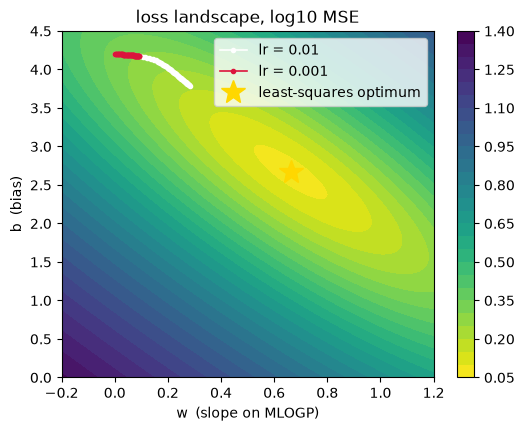

after 60 steps:  lr=0.01 → w=0.282 b=3.787  |  lr=0.001 → w=0.092 b=4.172  |  optimum w=0.662 b=2.668


In [ ]:
path_ok = gradient_descent(0.0, 4.2, lr=0.01)
path_slow = gradient_descent(0.0, 4.2, lr=0.001)

fig, ax = plt.subplots(figsize=(6, 4.5))
cs = ax.contourf(ws, bs, np.log10(L), levels=30, cmap="viridis_r")
ax.plot(*path_ok.T, "o-", c="white", ms=3, lw=1.2, label="lr = 0.01")
ax.plot(*path_slow.T, "o-", c="crimson", ms=3, lw=1.2, label="lr = 0.001")
ax.plot(lin1.coef_[0], lin1.intercept_, "*", c="gold", ms=18, label="least-squares optimum")
ax.set_xlabel("w  (slope on MLOGP)"); ax.set_ylabel("b  (bias)")
ax.set_title("loss landscape, log10 MSE")
ax.legend(loc="upper right")
fig.colorbar(cs, ax=ax)
plt.show()

print("after 60 steps:  lr=0.01 → w=%.3f b=%.3f  |  lr=0.001 → w=%.3f b=%.3f  |  optimum w=%.3f b=%.3f"
      % (*path_ok[-1], *path_slow[-1], lin1.coef_[0], lin1.intercept_))

✏️ **Exercise 3.** Re-run `gradient_descent` with `lr=0.05` and then `lr=0.2`. What happens, and what
does the landscape tell you about why?

In [ ]:
for lr in [0.01, 0.05, 0.2]:
    p = gradient_descent(0.0, 4.2, lr=lr, steps=60)
    w_, b_ = p[-1]
    final = np.mean((w_ * m_ + b_ - y_) ** 2)
    print(f"lr={lr:<5}  w={w_:8.3f}  b={b_:8.3f}  MSE={final:,.3f}"
          + ("   ← diverged" if not np.isfinite(final) or final > 100 else ""))

lr=0.01   w=   0.282  b=   3.787  MSE=1.615
lr=0.05   w=   0.567  b=   2.947  MSE=1.243
lr=0.2    w=-4430185416333150.000  b=-1503176916428909.250  MSE=157,941,292,857,317,655,274,354,720,636,928.000   ← diverged


<details><summary>Show answer</summary>

**Answer.** `lr=0.05` converges faster than 0.01; `lr=0.2` diverges to infinity. The valley in the
contour plot is a long, narrow ellipse - steep across, nearly flat along - because `MLOGP` is not
centred. A step that is sensible along the valley is far too large across it, so the iterate bounces
between the walls, each bounce bigger than the last.

This is the practical reason inputs get standardised before training, and the reason modern optimizers
(Adam, and the batch-normalisation layer pictured on slide 25) scale each direction separately. Nothing
about a "neural" network is involved: it is the geometry of a quadratic.

</details>

## Part 5 - Many neurons: a network

Slide 19 counts the parameters of a tiny network: `k` inputs, `N` neurons in a layer,
`nw = N(k+1)` weights. Slide 20 makes the universal-approximation claim - enough neurons and the right
weights approximate arbitrary functions - and slide 18 immediately attaches the price tag: *computing
cost, data hunger, overfitting* 👻.

We have 908 molecules and 6 descriptors. Let us buy neurons and see what we get.

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rows = []
for h in [1, 2, 5, 20, 100]:
    mlp = make_pipeline(StandardScaler(),
                        MLPRegressor(hidden_layer_sizes=(h,), max_iter=2000, random_state=RNG))
    r2 = cross_val_score(mlp, X, y, cv=cv, scoring="r2").mean()
    rows.append({"hidden units": h, "parameters": h * (6 + 1) + (h + 1), "CV R2": round(r2, 3)})
print(pd.DataFrame(rows).to_string(index=False))
print("\nlinear regression, same folds: CV R2 =", round(cross_val_score(LinearRegression(), X, y, cv=cv, scoring='r2').mean(), 3))

 hidden units  parameters  CV R2
            1           9  0.557
            2          17 -0.019
            5          41  0.577
           20         161  0.598
          100         801  0.571

linear regression, same folds: CV R2 = 0.557


❓ **Question.** Three things in that table are worth explaining. Why does **1 hidden unit** score the
same as linear regression? Why does **2** collapse? And why does **100** not beat **20**?

<details><summary>Show answer</summary>

**Answer.**

- **1 unit → 0.557, exactly the linear score.** With a single hidden neuron the network can only output a
  rescaled, once-bent version of one linear combination of the inputs - Part 3's result, restated. The
  kink again lands outside the data, so it *is* a linear regression.
- **2 units → -0.019, worse than predicting the mean.** This is not a capacity limit, it is an
  optimization failure: with ReLU activations a narrow layer can land in a state where both units output
  zero for every training molecule ("dead ReLUs"), the gradient is then zero, and training stops. Change
  the seed and it sometimes recovers. Slide 20 says a network *may* approximate arbitrary functions
  **with the correct weights** - finding them is a separate, non-convex problem, and this row is what the
  caveat looks like in practice.
- **100 units → 0.571, below 20 units' 0.598.** We have 908 rows and six descriptors. Extra capacity
  cannot invent information that is not in the data; it only adds ways to fit the noise. The ceiling here
  is set by the data, not by the architecture.

Deep learning's famous wins came with 10⁵-10⁹ training examples. On a 908-row table, a neural network is
a reasonable model and not a magic one - which is exactly the "orders of magnitude" literacy that
the take-home slide of class 3 asks for.

</details>

## Part 6 - Overfitting, and why the test set exists

Slide 26 shows two curves through the same points and asks which you prefer. Slide 28 draws the answer:
the training loss keeps falling while the test loss turns around.

Let us produce that figure from our own data. We take a deliberately oversized network - two layers of
256 units, ~70,000 parameters for 681 training molecules - and record both losses after every epoch.

In [ ]:
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=RNG)
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

net = MLPRegressor(hidden_layer_sizes=(256, 256), alpha=1e-7, max_iter=1, warm_start=True,
                   learning_rate_init=3e-3, random_state=RNG)

train_loss, test_loss = [], []
for epoch in range(400):
    net.fit(Xtr_s, ytr)                       # warm_start: one more epoch each time
    train_loss.append(np.mean((net.predict(Xtr_s) - ytr) ** 2))
    test_loss.append(np.mean((net.predict(Xte_s) - yte) ** 2))

best = int(np.argmin(test_loss))
print(f"parameters: {sum(c.size for c in net.coefs_) + sum(i.size for i in net.intercepts_):,}"
      f"   training molecules: {len(ytr)}")
print(f"best epoch {best + 1}: train MSE {train_loss[best]:.3f}, test MSE {test_loss[best]:.3f}")
print(f"epoch 400:     train MSE {train_loss[-1]:.3f}, test MSE {test_loss[-1]:.3f}")

parameters: 67,841   training molecules: 681
best epoch 218: train MSE 0.292, test MSE 0.885
epoch 400:     train MSE 0.231, test MSE 1.109


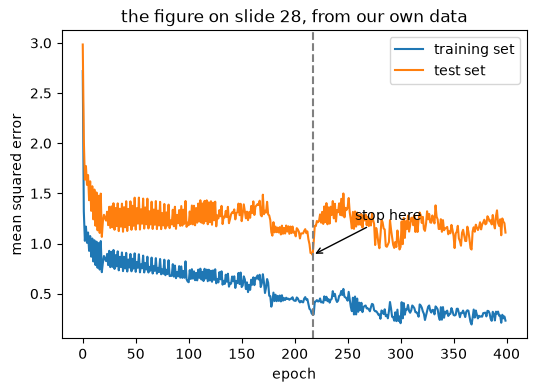

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(train_loss, label="training set")
ax.plot(test_loss, label="test set")
ax.axvline(best, ls="--", c="grey")
ax.annotate("stop here", (best, test_loss[best]), xytext=(best + 40, test_loss[best] + 0.35),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("epoch"); ax.set_ylabel("mean squared error")
ax.set_title("the figure on slide 28, from our own data")
ax.legend()
plt.show()

Training error falls to 0.231 and keeps going; test error bottoms out at 0.885 around epoch 218 and then
climbs to 1.109. Past that point the network is memorising its 681 molecules. That is slide 26's green
curve, drawn by a real optimizer.

❓ **Question (read slide 28 critically).** The slide says training stops "when loss on the test set is
minimized". We just did that. What is now wrong with calling 0.885 our estimate of how the model will
perform on new chemicals?

<details><summary>Show answer</summary>

**Answer.** We chose a hyperparameter - when to stop - by looking at the test set, so the test set helped
build the model and is no longer independent of it. The reported 0.885 is the *minimum* of a noisy curve,
which is optimistically biased for the same reason the maximum of 400 coin-flip runs is not a fair
estimate of a coin.

The fix is three splits: **train** to fit the weights, **validation** to pick when to stop and how wide
to go, **test** touched exactly once at the end. Slide 28's two-way picture is the right intuition and
the wrong protocol, and the distinction is the single most common hole in a student thesis.

How badly a single split can mislead is measured in Part 9.

</details>

### Playground: overfitting you can see

Six descriptors are hard to picture. Let us go down to **one dimension** with a toy problem where we
*know* the true curve: 20 noisy "measurements" of a dose-response-like curve. We fit polynomials
of increasing **degree** (degree 1 = straight line, degree 15 = very flexible curve), optionally with
a **ridge** penalty `alpha` on large coefficients (the same idea as `alpha` in the neural networks
of class 2).

`poly_playground()` draws two panels:
* **left**: the data, the true curve and the fitted polynomial. The faint red curves are the same
  model fitted on 20 *other* random samples of the same size: how much the fit changes from one
  dataset to the next is the **variance** of the model.
* **right**: training and test error for every degree 0-20 (median over the 21 training sets),
  with the current degree marked. The
  dotted line is the noise level: no model can do better than that on new data.

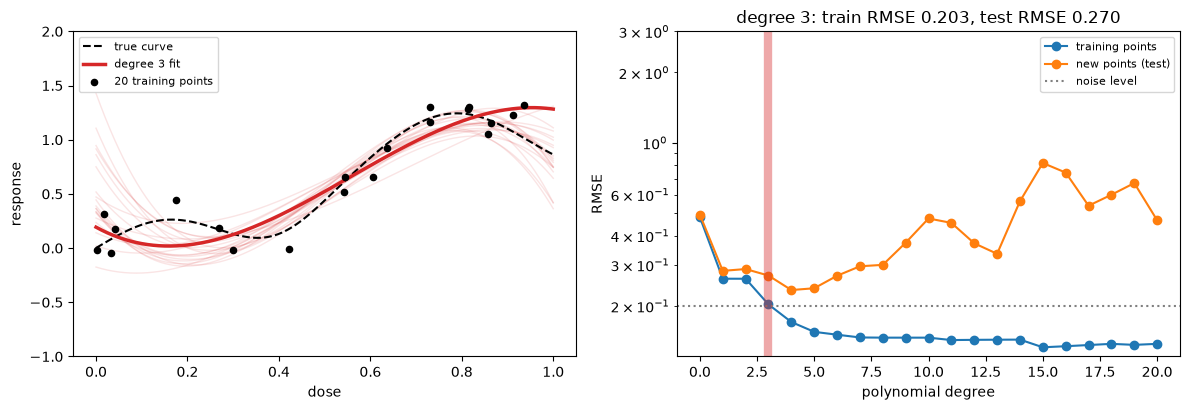

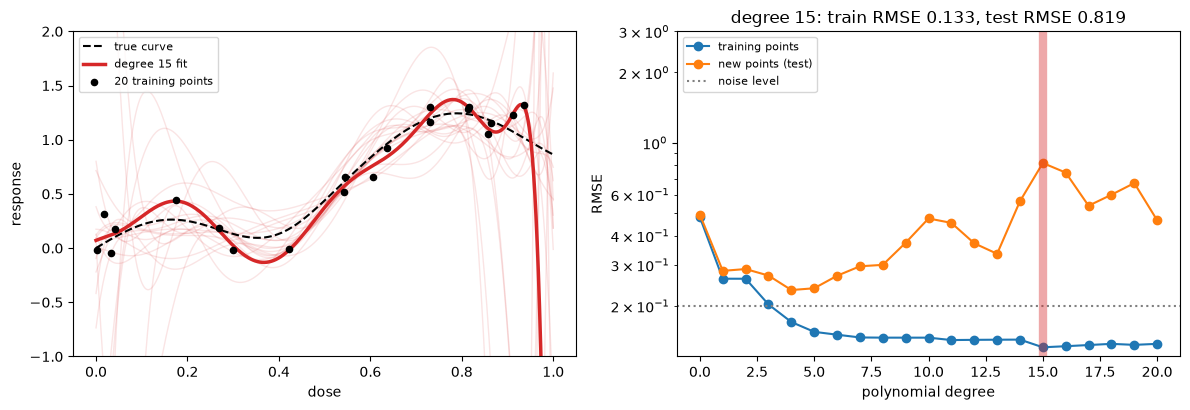

In [ ]:
# @title Support code: the polynomial playground
def true_curve(x):
    """The 'truth' we pretend not to know: a smooth dose-response-like curve."""
    return 1 / (1 + np.exp(-15 * (x - 0.45))) + 0.25 * np.sin(10 * x)

def make_toy(n, noise, seed):
    """n noisy measurements of true_curve at random x in [0, 1]."""
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(0, 1, n))
    return x, true_curve(x) + rng.normal(0, noise, n)

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

def poly_model(degree, alpha):
    reg = Ridge(alpha=alpha) if alpha > 0 else LinearRegression()
    return make_pipeline(PolynomialFeatures(degree), StandardScaler(), reg)

def poly_playground(degree=3, n_train=20, noise=0.2, alpha=0.0, seed=0, show_variance=True):
    x_tr, y_tr = make_toy(n_train, noise, seed)
    x_te, y_te = make_toy(500, noise, seed + 1000)            # fresh data from the same "experiment"
    grid = np.linspace(0, 1, 400)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

    # 20 other training sets of the same size, from the same "experiment"
    resamples = [make_toy(n_train, noise, 100 * seed + s) for s in range(1, 21)]
    if show_variance:
        for xs, ys in resamples:
            ax1.plot(grid, poly_model(degree, alpha).fit(xs[:, None], ys).predict(grid[:, None]),
                     color="tab:red", alpha=0.12, lw=1)
    model = poly_model(degree, alpha).fit(x_tr[:, None], y_tr)
    ax1.plot(grid, true_curve(grid), "k--", lw=1.5, label="true curve")
    ax1.plot(grid, model.predict(grid[:, None]), color="tab:red", lw=2.5, label=f"degree {degree} fit")
    ax1.scatter(x_tr, y_tr, color="k", s=20, zorder=3, label=f"{n_train} training points")
    ax1.set_ylim(-1, 2); ax1.set_xlabel("dose"); ax1.set_ylabel("response"); ax1.legend(fontsize=8, loc="upper left")

    # error for every degree: median over the training sets (one set alone gives a bumpy curve)
    rmse = lambda m, x, y: np.sqrt(np.mean((m.predict(x[:, None]) - y) ** 2))
    degrees = range(0, 21)
    tr, te = [], []
    for d in degrees:
        fits = [(poly_model(d, alpha).fit(xs[:, None], ys), xs, ys) for xs, ys in [(x_tr, y_tr)] + resamples]
        tr.append(np.median([rmse(m, xs, ys) for m, xs, ys in fits]))
        te.append(np.median([rmse(m, x_te, y_te) for m, xs, ys in fits]))
    ax2.plot(degrees, tr, "o-", label="training points")
    ax2.plot(degrees, te, "o-", label="new points (test)")
    ax2.axhline(noise, color="grey", ls=":", label="noise level")
    ax2.axvline(degree, color="tab:red", alpha=0.4, lw=6)
    ax2.set_yscale("log"); ax2.set_ylim(top=3); ax2.set_xlabel("polynomial degree"); ax2.set_ylabel("RMSE")
    ax2.set_title(f"degree {degree}: train RMSE {tr[degree]:.3f}, test RMSE {te[degree]:.3f}")
    ax2.legend(fontsize=8)
    plt.tight_layout(); plt.show()

poly_playground(degree=3)
poly_playground(degree=15)

*Sliders:* in Jupyter or Colab with `ipywidgets` installed, the next cell shows sliders and redraws the figure when you release one. Without `ipywidgets`, just call the function with other values.

In [ ]:
# @title Sliders for the playground
try:
    from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider, Checkbox
    interact(poly_playground,
             degree=IntSlider(value=3, min=0, max=20, continuous_update=False),
             n_train=IntSlider(value=20, min=8, max=300, step=4, continuous_update=False),
             noise=FloatSlider(value=0.2, min=0.0, max=0.8, step=0.05, continuous_update=False),
             alpha=FloatLogSlider(value=1e-8, base=10, min=-8, max=2, continuous_update=False),
             seed=IntSlider(value=0, min=0, max=20, continuous_update=False),
             show_variance=Checkbox(value=True))
except ImportError:
    print("ipywidgets is not installed: call poly_playground(degree=..., n_train=..., noise=..., alpha=...) instead")

interactive(children=(IntSlider(value=3, continuous_update=False, description='degree', max=20), IntSlider(val…

✏️ **Exercise 4.** Play with the parameters and answer:
1. With 20 points, which degrees **underfit** and which **overfit**? Look at both panels and at
   the faint red curves.
2. Keep degree 15 and give it more data (`n_train=60`, then `200`). What happens to the faint curves
   and to the gap between training and test error?
3. Keep degree 15 and 20 points, and add regularisation (`alpha=1e-4`, `1e-2`, `1`). Which value
   works best? What happens with `alpha=100`?
4. Change `noise` to 0.05, then 0.5. Does the best degree change?

<details><summary>Show answer</summary>

**Answer.**
1. Degrees 0-3 **underfit**: degree 3 misses the small bump around dose 0.2, and training and test
   errors are both well above the noise level (high **bias**). Degrees 4-5 are best (test RMSE ≈ 0.24,
   close to the noise level 0.2). From about degree 7 the test error climbs: degree 15 has a training
   RMSE of 0.13, *below* the noise level (it is fitting the noise), and a test RMSE of 0.8. Its faint
   curves fan out wildly, especially at the edges where there are few points (high **variance**): a
   different sample of 20 points gives a completely different model. That is what overfitting means.
2. More data tames the flexible model: with 60 points the degree-15 test RMSE drops from 0.8 to ≈ 0.22,
   with 200 points to ≈ 0.20 (the noise level), and the faint curves collapse onto the true one.
   Overfitting is a property of the model *and* of the amount of data.
3. Any penalty removes the wild swings (test RMSE ≈ 0.27 with `alpha=1e-4` or `1e-2`, ≈ 0.25 with
   `alpha=1`, the best here). With `alpha=100` the curve flattens towards the mean (≈ 0.38): we are
   back to underfitting. Regularisation lets us use a flexible model and turn its flexibility down.
4. Yes. With little noise (0.05) the points themselves describe the curve, and the best degree is
   ≈ 7. With a lot of noise (0.5) even a cubic fits noise and the best "model" is a straight line
   (degree 1). The noisier the data, the simpler the model it can support.

</details>

## Part 7 - Featurization: the model is only as good as its inputs

Slide 29 asks what you do when the inputs are not already a row of numbers - molecules, structures,
surfaces, images - and lists the usual answers in chemoinformatics: descriptors, fingerprints, SMILES
strings, graphs. Our six descriptors *are* such a featurization; somebody chose them, and that choice
caps everything we have done today.

Two quick controls make the point.

In [ ]:
rng = np.random.default_rng(RNG)

control = {
    "real descriptors": cross_val_score(LinearRegression(), X, y, cv=cv, scoring="r2").mean(),
    "6 random numbers per molecule": cross_val_score(
        LinearRegression(), rng.normal(size=X.shape), y, cv=cv, scoring="r2").mean(),
    "real descriptors, shuffled labels": cross_val_score(
        LinearRegression(), X, rng.permutation(y), cv=cv, scoring="r2").mean(),
}
for k, v in control.items():
    print(f"{k:>35s}:  CV R2 = {v:+.3f}")

                   real descriptors:  CV R2 = +0.557
      6 random numbers per molecule:  CV R2 = -0.018
  real descriptors, shuffled labels:  CV R2 = -0.008


Both controls land at about **0.0** - slightly negative, since a model fitted on noise is worse than
predicting the mean. Useful calibration: **R² = 0 is what "learned nothing" looks like**, and a
cross-validated R² of 0.56 from six cheap numbers is a genuine signal, not an artefact of the machinery.

Run a control like this every time a model surprises you. It costs one line and it is the difference
between a result and a bug.

❓ **Question.** We spent the session on *which model* (line, neuron, network of 20, network of 100) and
the spread was 0.56 to 0.60. What would you change if you wanted 0.8?

<details><summary>Show answer</summary>

**Answer.** Not the model - the representation, or the data. Six descriptors are a lossy summary of a
molecule: two different compounds with the same six numbers are indistinguishable to every model in this
notebook, no matter how deep. Better options, in increasing order of effort: more descriptors
(deephERG, shown in class 2, uses 185 plus 100 learned embeddings); fingerprints or a graph representation that
keeps the topology; a representation **learned** from data rather than hand-crafted - which is precisely
the argument for CNNs (class 2) and for pretrained models (class 3).

That is where classes 2 and 3 go: class 2 asks how far flexible models get on a table like this one and
how to score them honestly; class 3 lets a network read raw protein sequence and learn its own features.

</details>

---

## Hands-on Class 1 ended here, we resume

# More on uncertainty estimation


Parts 1-7 followed the slides. Now suppose a regulator hands you this table and asks for a model: which
one, how good is it, and how do you know? We already met the pieces (a held-out set in Part 6,
cross-validation in Part 2); here we look inside them.

## Part 8 - One split, a baseline, and linear fits

To know whether a model is any good we must test it on chemicals it has **not seen**. We keep 25%
of the data aside as a **test set**.

Two metrics:
* **RMSE** (root mean squared error), in LC50 units: the typical size of an error.
* **R²**: fraction of the variance explained. 0 = no better than always predicting the mean, 1 = perfect.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

X = fish.drop(columns="LC50")          # the descriptors as a table again (Parts 2-7 used plain arrays)
y = fish["LC50"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RNG)
print(len(X_train), "training chemicals,", len(X_test), "test chemicals")

# the dumbest possible model: always predict the training mean
baseline = np.full(len(y_test), y_train.mean())
print(f"baseline  RMSE = {root_mean_squared_error(y_test, baseline):.3f}")

681 training chemicals, 227 test chemicals
baseline  RMSE = 1.399


LC50 = 2.57 + 0.70 * MLOGP
MLOGP only:  RMSE = 1.200   R2 = 0.264


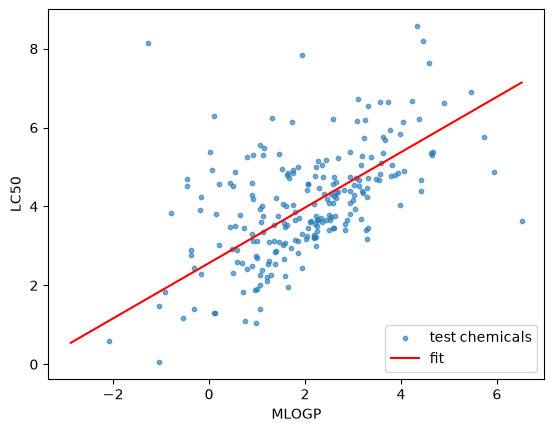

In [ ]:
lr1 = LinearRegression().fit(X_train[["MLOGP"]], y_train)
pred = lr1.predict(X_test[["MLOGP"]])
print(f"LC50 = {lr1.intercept_:.2f} + {lr1.coef_[0]:.2f} * MLOGP")
print(f"MLOGP only:  RMSE = {root_mean_squared_error(y_test, pred):.3f}   R2 = {r2_score(y_test, pred):.3f}")

xs = np.linspace(X["MLOGP"].min(), X["MLOGP"].max(), 50)
plt.scatter(X_test["MLOGP"], y_test, s=10, alpha=0.6, label="test chemicals")
plt.plot(xs, lr1.predict(pd.DataFrame({"MLOGP": xs})), "r", label="fit")
plt.xlabel("MLOGP"); plt.ylabel("LC50"); plt.legend();

✏️ **Exercise 5.** Fit a `LinearRegression` on **all six** descriptors (`X_train`) and report RMSE and
R² on the test set. Does it beat MLOGP alone?

In [ ]:
lr_all = LinearRegression().fit(X_train, y_train)
pred_all = lr_all.predict(X_test)
print(f"all six:  RMSE = {root_mean_squared_error(y_test, pred_all):.3f}   R2 = {r2_score(y_test, pred_all):.3f}")

all six:  RMSE = 1.045   R2 = 0.442


Raw coefficients cannot be compared with each other (different units). Fitting on standardised
descriptors makes each coefficient mean "change in LC50 per one standard deviation of the descriptor".

## Part 9 - Non-linear models and cross-validation

A straight line may be too simple. Two classic non-linear models:

* **k-nearest neighbours (kNN)**: predict the average LC50 of the *k* most similar training
  chemicals. Similarity = distance in descriptor space, so scaling matters!
* **Random forest (RF)**: average of many decision trees, each trained on a random resample.

A single train/test split is noisy (it depends on which chemicals ended up in the test set).
**5-fold cross-validation** splits the data in 5 parts, uses each part once as test set, and
averages the 5 scores.

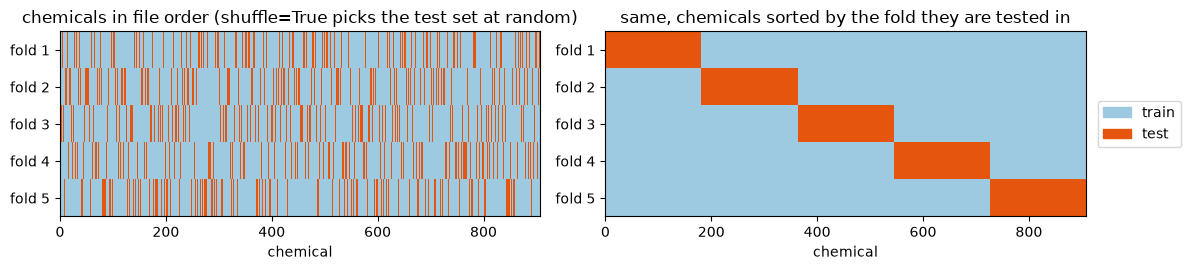

In [ ]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=RNG)

# which chemicals are in the test set of each fold?
fold_of = np.zeros(len(X), dtype=int)
role = np.zeros((cv.get_n_splits(), len(X)))           # 1 = test, 0 = train
for i, (train_idx, test_idx) in enumerate(cv.split(X)):
    role[i, test_idx] = 1
    fold_of[test_idx] = i

from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#9ecae1", "#e6550d"])           # train = blue, test = orange
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
axes[0].imshow(role, aspect="auto", cmap=cmap, interpolation="nearest")
axes[0].set_title("chemicals in file order (shuffle=True picks the test set at random)")
axes[1].imshow(role[:, np.argsort(fold_of, kind="stable")], aspect="auto", cmap=cmap, interpolation="nearest")
axes[1].set_title("same, chemicals sorted by the fold they are tested in")
for ax in axes:
    ax.set_yticks(range(5), [f"fold {i + 1}" for i in range(5)])
    ax.set_xlabel("chemical")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color="#9ecae1", label="train"), Patch(color="#e6550d", label="test")],
               loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "linear (MLOGP only)": ("MLOGP", LinearRegression()),
    "linear (all)":        (None, LinearRegression()),
    "kNN, k=10 (scaled)":  (None, make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10))),
    "random forest":       (None, RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1)),
}

results, fold_scores = {}, {}
for name, (cols, model) in models.items():
    Xm = X[[cols]] if cols else X
    r2 = cross_val_score(model, Xm, y, cv=cv, scoring="r2")
    results[name] = (r2.mean(), r2.std())
    fold_scores[name] = r2
    print(f"{name:22s} R2 = {r2.mean():.3f} +/- {r2.std():.3f}")

linear (MLOGP only)    R2 = 0.408 +/- 0.053
linear (all)           R2 = 0.557 +/- 0.043
kNN, k=10 (scaled)     R2 = 0.619 +/- 0.023
random forest          R2 = 0.604 +/- 0.027


Each fold gives its own score. How different are they? And how unusual was the single split of
Part 8? Let us repeat that split with 200 different random seeds.

200 splits: R2 = 0.566 +/- 0.049, range 0.41 - 0.69
splits worse than ours: 1.5%


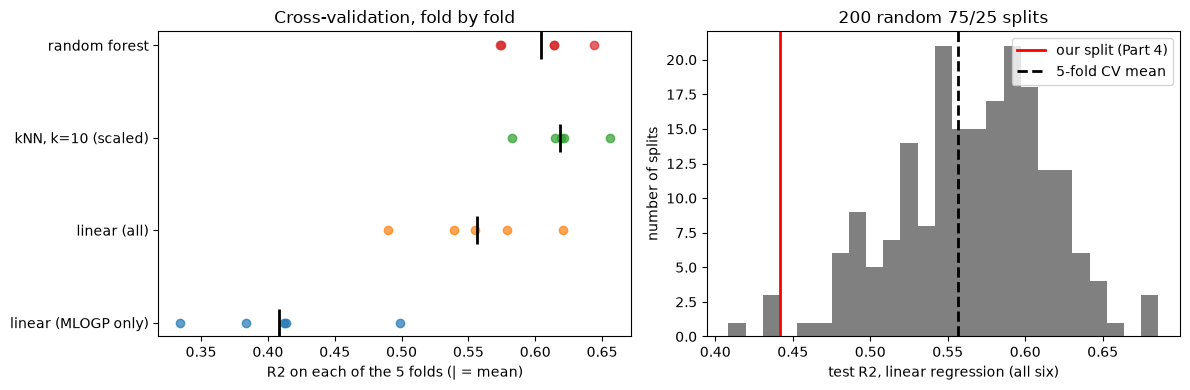

In [ ]:
# @title Support code: fold-by-fold scores and 200 random splits (figure)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for i, (name, r2) in enumerate(fold_scores.items()):
    ax1.plot(r2, np.full(5, i), "o", alpha=0.7)
    ax1.plot(r2.mean(), i, "k|", ms=20, mew=2)
ax1.set_yticks(range(len(fold_scores)), list(fold_scores))
ax1.set_xlabel("R2 on each of the 5 folds (| = mean)")
ax1.set_title("Cross-validation, fold by fold")

split_r2 = []
for seed in range(200):
    Xa_, Xb_, ya_, yb_ = train_test_split(X, y, test_size=0.25, random_state=seed)
    split_r2.append(r2_score(yb_, LinearRegression().fit(Xa_, ya_).predict(Xb_)))
split_r2 = np.array(split_r2)

ax2.hist(split_r2, bins=25, color="grey")
ax2.axvline(r2_score(y_test, pred_all), color="r", lw=2, label="our split (Part 4)")
ax2.axvline(fold_scores["linear (all)"].mean(), color="k", ls="--", lw=2, label="5-fold CV mean")
ax2.set_xlabel("test R2, linear regression (all six)"); ax2.set_ylabel("number of splits")
ax2.set_title("200 random 75/25 splits"); ax2.legend()
plt.tight_layout()
print(f"200 splits: R2 = {split_r2.mean():.3f} +/- {split_r2.std():.3f}, "
      f"range {split_r2.min():.2f} - {split_r2.max():.2f}")
print(f"splits worse than ours: {(split_r2 < r2_score(y_test, pred_all)).mean():.1%}")

❓ Was the split of Part 8 (the red line, labelled "Part 4" in the figure) representative? Which number would you report for the linear model, and
can you say that the random forest is better than kNN?

<details><summary>Show answer</summary>

**Answer.** No, it was unlucky: R² ≈ 0.44 falls in the worst 2% of the 200 random splits, which
average ≈ 0.57 ± 0.05. Whatever we conclude from one split of 227 chemicals can be off by
±0.1 in R². The cross-validated value (≈ 0.56) agrees with the average over many splits and is the
one to report. Fold to fold, R² varies by about ±0.05 for every model. That is as large as the
differences between kNN, RF and the linear model, so the ranking of the three non-trivial models is
*not* solid. Only "MLOGP alone is worse" is clear.

</details>

✏️ **Exercise 6.** Add kNN **without** the `StandardScaler` to the comparison. What happens, and why?

In [ ]:
knn_raw = KNeighborsRegressor(n_neighbors=10)
r2 = cross_val_score(knn_raw, X, y, cv=cv, scoring="r2")
print(f"kNN unscaled R2 = {r2.mean():.3f}")

kNN unscaled R2 = 0.570


✏️ **Exercise 7.** Try a few values of `n_neighbors` for the scaled kNN (e.g. 1, 3, 10, 30, 100).
What happens with very small and very large *k*?

<details><summary>Show answer</summary>

**Answer (6).** Without scaling R² drops (≈0.62 → 0.57): distances are dominated by the descriptors with
the largest numeric range, so the "nearest" chemicals are not really the most similar.
**Answer (7).** k=1 copies the single nearest chemical, including its noise (overfitting);
very large k averages over half the dataset and flattens everything towards the mean (underfitting).
The best is somewhere in between.

</details>

In [ ]:
for k in [1, 3, 10, 30, 100]:
    m = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    print(f"k={k:3d}  R2 = {cross_val_score(m, X, y, cv=cv, scoring='r2').mean():.3f}")

k=  1  R2 = 0.406
k=  3  R2 = 0.584
k= 10  R2 = 0.619
k= 30  R2 = 0.597
k=100  R2 = 0.520


The same question as a picture: the error on the **training** folds and on the **held-out** folds
as *k* changes. Small *k* = a flexible, "wiggly" model, large *k* = a smooth one.

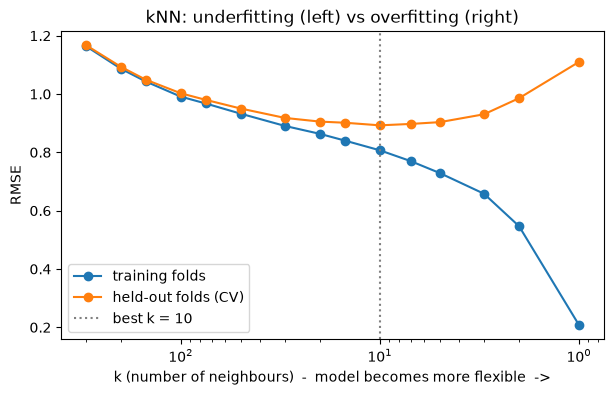

In [ ]:
# @title Support code: training vs held-out error for kNN (figure)
from sklearn.model_selection import cross_validate

ks = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300]
train_rmse, cv_rmse = [], []
for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    s = cross_validate(m, X, y, cv=cv, scoring="neg_root_mean_squared_error", return_train_score=True)
    train_rmse.append(-s["train_score"].mean())
    cv_rmse.append(-s["test_score"].mean())

best = ks[int(np.argmin(cv_rmse))]
plt.figure(figsize=(7, 4))
plt.plot(ks, train_rmse, "o-", label="training folds")
plt.plot(ks, cv_rmse, "o-", label="held-out folds (CV)")
plt.axvline(best, color="grey", ls=":", label=f"best k = {best}")
plt.xscale("log"); plt.gca().invert_xaxis()     # left: simple model, right: flexible model
plt.xlabel("k (number of neighbours)  -  model becomes more flexible  ->")
plt.ylabel("RMSE"); plt.legend()
plt.title("kNN: underfitting (left) vs overfitting (right)");

❓ Why is the training error at *k* = 1 not zero? Where does the gap between the two curves start
to open?

<details><summary>Show answer</summary>

**Answer.** With *k* = 1 each training chemical is its own nearest neighbour, so the training error
should be zero. It is not, because some chemicals share **identical descriptors** but have different
LC50 (the model cannot tell them apart; the average gives the remaining error). On the left
(*k* ≥ 100) both errors are high and almost equal: underfitting. Going right, the training error keeps
falling, but the held-out error reaches its minimum around *k* ≈ 10 (RMSE ≈ 0.89) and then rises again:
overfitting. The growing gap between the two curves is the sign of a model that memorises.

</details>

## The bias-variance tradeoff

We have just seen (yet another) example of the all-important *bias-variance tradeoff*.

| Model complexity | Bias         | Variance | Typical behavior    |
| ---------------- | ------------ | -------- | ------------------- |
| Very low         | High         | Low      | Underfitting        |
| Moderate         | Moderate/low | Moderate | Good generalization |
| Very high        | Low          | High     | Overfitting         |


Would **more data** help? A **learning curve** trains each model on bigger and bigger subsets and
measures the error on the training data and on held-out data.

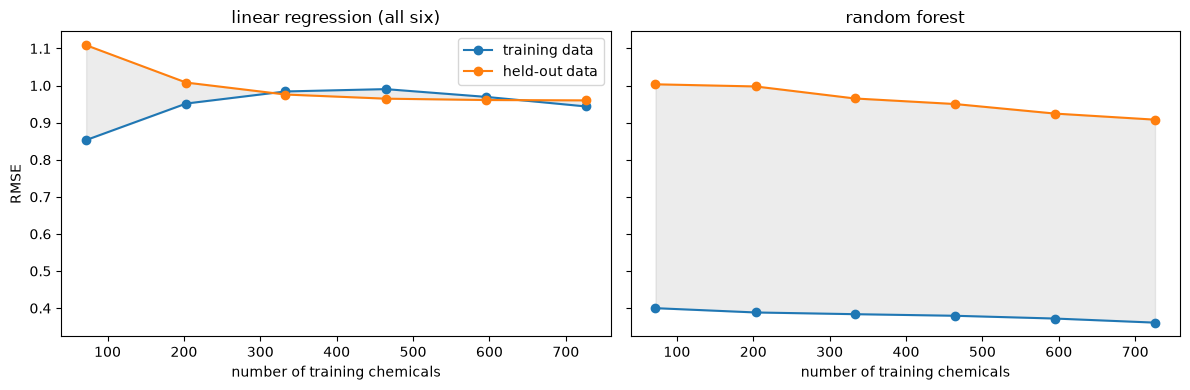

In [ ]:
# @title Support code: learning curves (figure)
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, model) in zip(axes, {
        "linear regression (all six)": LinearRegression(),
        "random forest": RandomForestRegressor(n_estimators=100, random_state=RNG, n_jobs=-1)}.items()):
    sizes, tr, te = learning_curve(model, X, y, cv=cv, train_sizes=np.linspace(0.1, 1, 6),
                                   scoring="neg_root_mean_squared_error")
    ax.plot(sizes, -tr.mean(axis=1), "o-", label="training data")
    ax.plot(sizes, -te.mean(axis=1), "o-", label="held-out data")
    ax.fill_between(sizes, -tr.mean(axis=1), -te.mean(axis=1), alpha=0.15, color="grey")
    ax.set_title(name); ax.set_xlabel("number of training chemicals")
axes[0].set_ylabel("RMSE"); axes[0].legend()
plt.tight_layout()

❓ For which model would testing more chemicals on fish be worth the money?

<details><summary>Show answer</summary>

**Answer.** For the **linear model** the two curves have already met (RMSE ≈ 0.96 on both) after
a few hundred chemicals. It is limited by its own simplicity (high **bias**), and more data will not
help. The **random forest** fits its training data much better than new data (≈ 0.36 vs ≈ 0.91:
high **variance**), and its held-out error is still going down at 726 chemicals. More data would
probably still improve it. The shaded gap is how much the model has memorised.

</details>

## Part 10 - What did the model learn?

**Permutation importance**: shuffle one descriptor in the test set and measure how much the score
drops. If the model relies on that descriptor, scrambling it hurts.

In [ ]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=RNG, scoring="r2")
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values()
print(importance)
importance.plot.barh()
plt.xlabel("drop in R2 when shuffled");

NameError: name 'rf' is not defined

❓ Does the random forest agree with the correlations of Part 1?

<details><summary>Show answer</summary>

**Answer.** Yes: `MLOGP` is by far the most important, followed by `SM1_Dz` and `GATS1i`. The
data mining (correlations) and the model tell the same biological story: lipophilicity first.

</details>

# Part 11 - A neural network for toxicity  (Optional)

A **multi-layer perceptron (MLP)** is a stack of layers. Each *neuron* computes a weighted sum of its
inputs and passes it through a non-linear *activation* (here ReLU: $\max(0, z)$):

$$ h_j = \mathrm{ReLU}\Big(\sum_i w_{ji} x_i + b_j\Big), \qquad \hat y = \sum_j v_j h_j + c $$

The weights $w, v$ and biases $b, c$ start random and are adjusted step by step (gradient descent)
to reduce the squared error on the training data. With enough hidden neurons an MLP can
approximate any smooth function - which is both its strength and its danger.

```
 6 descriptors  ->  [32 hidden neurons, ReLU]  ->  1 output (LC50)
```

In [ ]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

fish = load_fish()
X, y = fish.drop(columns="LC50"), fish["LC50"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RNG)

mlp = make_pipeline(
    StandardScaler(),                     # neural nets also want scaled inputs
    MLPRegressor(hidden_layer_sizes=(32,), max_iter=3000, random_state=RNG),
)
mlp.fit(X_train, y_train)
print(f"MLP test R2 = {r2_score(y_test, mlp.predict(X_test)):.3f}")

The network was trained iteratively. `loss_curve_` stores the training loss after each pass over
the data (*epoch*).

In [ ]:
net = mlp[-1]
plt.plot(net.loss_curve_)
plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("training loss (squared error / 2)")
plt.title(f"{net.n_iter_} epochs");

✏️ **Exercise A.1.** Compare the MLP with the random forest of class 1 (Part 9) using the same 5-fold
cross-validation (`cv` below). Which one wins?

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=RNG)
rf = RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1)

r2_mlp = cross_val_score(mlp, X, y, cv=cv, scoring="r2")
r2_rf = cross_val_score(rf, X, y, cv=cv, scoring="r2")
print(f"MLP R2 = {r2_mlp.mean():.3f}   RF R2 = {r2_rf.mean():.3f}")

### What function did each model learn?

The models live in 6 dimensions, so we cannot draw them. We can take a **slice**: vary `MLOGP` and
keep the other five descriptors fixed at their median. Each curve is the predicted LC50 along that slice.

In [ ]:
# @title Support code: the function each model learned (figure)
from sklearn.linear_model import LinearRegression

line = pd.DataFrame(np.tile(X_train.median().values, (300, 1)), columns=X.columns)
line["MLOGP"] = np.linspace(X["MLOGP"].min() - 1, X["MLOGP"].max() + 1, 300)

wide_mlp = make_pipeline(StandardScaler(),
                         MLPRegressor(hidden_layer_sizes=(512, 512), alpha=1e-4,
                                      max_iter=2000, random_state=RNG))
fitted = {
    "linear regression": LinearRegression(),
    "random forest": RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1),
    "MLP (32)": mlp,                                   # already trained above
    "MLP (512, 512), no regularisation": wide_mlp,
}
plt.figure(figsize=(8, 5))
plt.scatter(X_train["MLOGP"], y_train, s=6, c="lightgrey", label="training chemicals")
for name, m in fitted.items():
    if m is not mlp:
        m.fit(X_train, y_train)
    plt.plot(line["MLOGP"], m.predict(line), lw=2, label=name)
plt.axvspan(line["MLOGP"].min(), X["MLOGP"].min(), color="k", alpha=0.07)
plt.axvspan(X["MLOGP"].max(), line["MLOGP"].max(), color="k", alpha=0.07, label="outside the data")
plt.xlabel("MLOGP (other descriptors at their median)"); plt.ylabel("predicted LC50")
plt.legend(fontsize=8);

❓ Describe the shape of each curve. What happens outside the range of the data (grey bands)?

**Answer.** Linear regression is a straight line everywhere. The random forest is a **staircase**:
each tree cuts the axis into intervals and predicts a constant in each, and beyond the data it goes
**flat** (it can never predict outside the range of the training LC50). The MLP is made of ReLUs,
so it is **piecewise linear**: smooth bends inside the data, then it continues as a straight line
outside, extrapolating in whatever direction the last piece pointed. Both MLPs bend **upwards** at low MLOGP,
predicting that very hydrophilic chemicals are *more* toxic: there are few training chemicals there,
the curve is not constrained, and the result is biologically implausible. The big unregularised
network bends more and has small wiggles where it follows individual chemicals: overfitting, seen directly.
None of the models can be trusted in the grey bands; QSAR guidelines call the region where a
model is valid its **applicability domain**.

### How big should the network be?

We train networks with two hidden layers of increasing width and compare the R² on the
**training** set with the R² on the **test** set.

In [ ]:
sizes = [1, 2, 4, 8, 32, 128, 512]

def size_sweep(alpha):
    """Train/test R2 for 2-hidden-layer MLPs of each width; alpha = L2 penalty on the weights."""
    rows = []
    for h in sizes:
        m = make_pipeline(StandardScaler(),
                          MLPRegressor(hidden_layer_sizes=(h, h), alpha=alpha,
                                       max_iter=2000, random_state=RNG))
        m.fit(X_train, y_train)
        rows.append((h, r2_score(y_train, m.predict(X_train)), r2_score(y_test, m.predict(X_test))))
    return pd.DataFrame(rows, columns=["width", "train R2", "test R2"]).set_index("width")

sweep = size_sweep(alpha=1e-4)          # almost no regularisation
sweep.plot(logx=True, marker="o")
plt.ylabel("R2"); plt.title("alpha = 0.0001");
sweep

❓ What happens to the gap between training and test R² as the network grows? What is this called?

✏️ **Exercise A.2.** `alpha` adds a penalty on large weights (*L2 regularisation*, "weight decay").
Run `size_sweep(alpha=1.0)` and compare with the plot above.

In [ ]:
sweep_reg = size_sweep(alpha=1.0)
ax = sweep.plot(logx=True, marker="o", style="--", alpha=0.5)
sweep_reg.plot(logx=True, marker="o", ax=ax)
plt.legend(["train, alpha=1e-4", "test, alpha=1e-4", "train, alpha=1", "test, alpha=1"])
plt.ylabel("R2");
sweep_reg

**Answer.** Without regularisation, the bigger networks fit the training set better and better
(train R² up to ≈ 0.93) while the test R² does not improve: this is **overfitting** - the network
memorises the 681 training chemicals, noise included. With `alpha=1.0` the training R² stays
lower (≈ 0.8), the gap shrinks, and the large networks generalise best (test R² ≈ 0.55).
On a small table of 6 descriptors, an MLP does **not** beat a random forest (≈ 0.58 vs ≈ 0.60
in cross-validation). Neural networks shine with large data and with raw, structured inputs such as
sequences and images - which is where we go next.

# Summary

Parts 8-10, the same data as a practical problem:

* One train/test split is a noisy estimate (R² 0.44 on ours, against ≈ 0.57 on average over 200 random
  splits). **Cross-validation** uses every chemical once as test data and is the number to report.
* Non-linear models (kNN, random forest) gain a little over linear regression (R² ≈ 0.56 → 0.60);
  distance-based models need **scaled** inputs.
* Training error always goes down with model flexibility; held-out error does not. The gap between
  them (kNN with small *k*, the random forest, a degree-15 polynomial) is **overfitting**.
* The random forest relies on the same descriptor the correlations pointed to: lipophilicity first.

**The one-line version.** A neural network is a stack of regressions fitted by walking downhill, it needs
more data than this table has, and the thing that limits your result is usually the representation, not
the architecture.

## Your turn: water fleas (homework)

`load_aquatic()` gives 546 chemicals with 8 descriptors and their 48-hour LC50 for *Daphnia magna*.

1. Repeat Parts 2 and 5: linear regression, then MLPs of a few widths, 5-fold cross-validated. (A plain
   linear fit gets CV R² ≈ 0.46 - use that to check your pipeline.)
2. `MLOGP` appears in both datasets. Is its coefficient similar for fish and for *Daphnia*? Should it be?
3. Harder, and the question a regulator would ask: train on the fish data and predict the *Daphnia*
   labels for the chemicals the two datasets have in common. You will need to decide how to match
   molecules when all you have are descriptors - and the difficulty of that step is itself the lesson.

## References and data sources

**Data.**
- M. Cassotti, D. Ballabio, R. Todeschini, V. Consonni, *A similarity-based QSAR model for predicting
  acute toxicity towards the fathead minnow (Pimephales promelas)*, SAR QSAR Environ. Res. 26 (2015)
  217-243. UCI ML Repository, "QSAR fish toxicity"
  (https://archive.ics.uci.edu/dataset/504/qsar+fish+toxicity).
- M. Cassotti, D. Ballabio, V. Consonni, A. Mauri, I. V. Tetko, R. Todeschini, *Prediction of acute
  aquatic toxicity toward Daphnia magna by using the GA-kNN method*, ATLA 42 (2014) 31-41. UCI ML
  Repository, "QSAR aquatic toxicity".

**Mentioned in the slides.**
- 3Blue1Brown, *Neural networks* (video series) - the backpropagation illustration on slide 25.
- A. Cherkasov *et al.*, *QSAR modeling: where have you been? Where are you going to?*,
  J. Med. Chem. 57 (2014) 4977 - context for what these descriptors are.
- A. D. White, *Deep Learning for Molecules and Materials*, dmol.pub - the self-study
  recommendation of class 3, and the natural next step after this notebook.

**Software.** scikit-learn (Pedregosa *et al.*, JMLR 12 (2011) 2825), numpy, pandas, matplotlib.
